# Within-gene structural confidence

## 1. Data acquisition

ClinVar GRCh38 release July 20, 2026 supplies missense classifications; the fixed AlphaMissense release supplies predictions. UCSC hg38 100-way phyloP and GENCODE v45 provide conservation context. The exact raw source URLs and hashes are verified below. Residue confidence comes from the official AlphaFold DB v6 human reference-proteome PDB archive. CA B-factors contain per-residue pLDDT; any existing individual v6 JSON responses are checked for exact agreement. Mappings outside the reference proteome use explicitly acquired v6 JSON files.


In [1]:
from pathlib import Path
from collections import Counter,defaultdict
from io import BytesIO
import os,sys,json,gzip,csv,re,hashlib,time,urllib.request,ssl,zipfile,math,platform
for key in ['OMP_NUM_THREADS','OPENBLAS_NUM_THREADS','MKL_NUM_THREADS']:os.environ[key]='1'
import numpy as np
import pandas as pd
from scipy.stats import spearmanr,wilcoxon
from sklearn.metrics import roc_auc_score,average_precision_score
from Bio.Align import substitution_matrices
import statsmodels.api as sm
import statsmodels.formula.api as smf
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from IPython.display import display,Image,Markdown
RAW=Path(os.environ.get('AM_RAW_INPUTS','am_public_inputs')).expanduser().resolve()
OUTPUT=Path('calculated_outputs').resolve();RAW.mkdir(parents=True,exist_ok=True);OUTPUT.mkdir(parents=True,exist_ok=True)
STARTED=time.time()
pd.set_option('display.max_colwidth',100)
def show_figure(fig):
    buffer=BytesIO();fig.savefig(buffer,format='png',dpi=150,bbox_inches='tight');display(Image(data=buffer.getvalue()))


In [2]:
SOURCES = [{'id': 'am_hg38',
  'path': 'inputs/raw/AlphaMissense_hg38.tsv.gz',
  'url': 'https://storage.googleapis.com/dm_alphamissense/AlphaMissense_hg38.tsv.gz',
  'sha256': '0516cfd71c0767ac8f9c469252d429000e94e02c008b6e3a46d4b4646fcd3475',
  'bytes': 642961469},
 {'id': 'clinvar_vcf',
  'path': 'inputs/raw/clinvar_20260720.vcf.gz',
  'url': 'https://ftp.ncbi.nlm.nih.gov/pub/clinvar/vcf_GRCh38/archive_2.0/2026/clinvar_20260720.vcf.gz',
  'sha256': 'ecedd212660c7e04c94ffdf8d516ec6881283ab501f4b7700b87e82c65e4551b',
  'bytes': 192806479},
 {'id': 'gencode45',
  'path': 'inputs/raw/gencode.v45.basic.annotation.gtf.gz',
  'url': 'https://ftp.ebi.ac.uk/pub/databases/gencode/Gencode_human/release_45/gencode.v45.basic.annotation.gtf.gz',
  'sha256': 'c6e289b65241fe7a08bf655e4aced3ec8480d166cf83febc9d133db1a04034bb',
  'bytes': 29623361},
 {'id': 'phylop100way',
  'path': 'inputs/raw/hg38.phyloP100way.bw',
  'url': 'https://hgdownload.soe.ucsc.edu/goldenPath/hg38/phyloP100way/hg38.phyloP100way.bw',
  'sha256': '445fa3473c94fc209a6854692143371a57c05a387241e3de55933032ac024973',
  'bytes': 9870053206}]

def sha256_file(path):
    h=hashlib.sha256()
    with Path(path).open('rb') as f:
        for block in iter(lambda:f.read(8*1024*1024),b''):h.update(block)
    return h.hexdigest()
def acquire(source):
    p=RAW/Path(source['path']).name
    if not p.exists():
        partial=p.with_name(p.name+'.notebook-part')
        req=urllib.request.Request(source['url'],headers={'User-Agent':'AlphaMissense-analysis/1.0'})
        # ProteinGym's server omits an intermediate certificate; exact archive
        # content is authenticated by the fixed SHA256 below.
        context=ssl._create_unverified_context() if 'marks.hms.harvard.edu' in source['url'] and source.get('sha256') else None
        with urllib.request.urlopen(req,timeout=180,context=context) as r,partial.open('wb') as f:
            while True:
                b=r.read(4*1024*1024)
                if not b:break
                f.write(b)
        if source.get('sha256') and sha256_file(partial)!=source['sha256']:raise ValueError('Download checksum mismatch: '+p.name)
        if source.get('bytes') and partial.stat().st_size!=source['bytes']:raise ValueError('Download size mismatch: '+p.name)
        partial.replace(p)
    h=sha256_file(p)
    if source.get('sha256') and h!=source['sha256']:raise ValueError('Input checksum mismatch: '+p.name)
    if source.get('bytes') and p.stat().st_size!=source['bytes']:raise ValueError('Input size mismatch: '+p.name)
    return dict(path=p.name,url=source['url'],sha256=h,bytes=p.stat().st_size)
source_receipts=[acquire(s) for s in SOURCES]
display(pd.DataFrame(source_receipts))


,path,url,sha256,bytes
0,AlphaMissense_hg38.tsv.gz,https://storage.googleapis.com/dm_alphamissense/AlphaMissense_hg38.tsv.gz,0516cfd71c0767ac8f9c469252d429000e94e02c008b6e3a46d4b4646fcd3475,642961469
1,clinvar_20260720.vcf.gz,https://ftp.ncbi.nlm.nih.gov/pub/clinvar/vcf_GRCh38/archive_2.0/2026/clinvar_20260720.vcf.gz,ecedd212660c7e04c94ffdf8d516ec6881283ab501f4b7700b87e82c65e4551b,192806479
2,gencode.v45.basic.annotation.gtf.gz,https://ftp.ebi.ac.uk/pub/databases/gencode/Gencode_human/release_45/gencode.v45.basic.annotatio...,c6e289b65241fe7a08bf655e4aced3ec8480d166cf83febc9d133db1a04034bb,29623361
3,hg38.phyloP100way.bw,https://hgdownload.soe.ucsc.edu/goldenPath/hg38/phyloP100way/hg38.phyloP100way.bw,445fa3473c94fc209a6854692143371a57c05a387241e3de55933032ac024973,9870053206


In [3]:
# Human reference-proteome structures from the official version6 release.
# The archive's PDB CA B-factors store the same residue pLDDT values as
# AF-<accession>-F1-confidence_v6.json; an overlap check runs below.
from concurrent.futures import ThreadPoolExecutor, as_completed
import requests, threading, tarfile
AF_ARCHIVE_URL = 'https://ftp.ebi.ac.uk/pub/databases/alphafold/v6/UP000005640_9606_HUMAN_v6.tar'
AF_ARCHIVE_BYTES = 5177506304
AF_ARCHIVE_SHA256 = None  # A first acquisition records the content fingerprint.
AF_ARCHIVE = RAW / 'UP000005640_9606_HUMAN_v6.tar'
AF_ARCHIVE_RECEIPT = RAW / 'UP000005640_9606_HUMAN_v6.source.json'
AF_PARTS = RAW / 'UP000005640_9606_HUMAN_v6.parts'
AF_PARTS.mkdir(exist_ok=True)
AF_CHUNK_BYTES = 32 * 1024 * 1024
AF_DOWNLOAD_WORKERS = int(os.environ.get('AF_DOWNLOAD_WORKERS', '16'))
_sessions = threading.local()
def acquire_af_part(start):
    end = min(start + AF_CHUNK_BYTES, AF_ARCHIVE_BYTES) - 1
    part = AF_PARTS / f'{start:012d}-{end:012d}.part'
    receipt_path = part.with_suffix('.json')
    if part.exists() and receipt_path.exists():
        receipt = json.loads(receipt_path.read_text())
        if (receipt.get('url') == AF_ARCHIVE_URL and receipt.get('start') == start
            and receipt.get('end') == end and part.stat().st_size == end-start+1
            and sha256_file(part) == receipt.get('sha256')):
            return receipt
    for attempt in range(5):
        temporary = part.with_suffix('.partial')
        try:
            if not hasattr(_sessions, 'http'):
                _sessions.http = requests.Session()
            with _sessions.http.get(AF_ARCHIVE_URL, headers={
                'Range': f'bytes={start}-{end}', 'User-Agent': 'AlphaMissense-analysis/1.0'
            }, timeout=(30,180), stream=True) as response:
                response.raise_for_status()
                expected_range = f'bytes {start}-{end}/{AF_ARCHIVE_BYTES}'
                if response.status_code != 206 or response.headers.get('Content-Range') != expected_range:
                    raise ValueError('Archive server did not return the requested byte range')
                with temporary.open('wb') as handle:
                    for block in response.iter_content(1024*1024):
                        if block: handle.write(block)
            if temporary.stat().st_size != end-start+1:
                raise ValueError('Incomplete archive range')
            receipt = {'url': AF_ARCHIVE_URL, 'start': start, 'end': end,
                       'sha256': sha256_file(temporary), 'bytes': end-start+1}
            temporary.replace(part)
            receipt_path.write_text(json.dumps(receipt, indent=2))
            return receipt
        except Exception:
            if attempt == 4: raise
            time.sleep(5*(attempt+1))
if not AF_ARCHIVE.exists():
    starts = list(range(0, AF_ARCHIVE_BYTES, AF_CHUNK_BYTES))
    with ThreadPoolExecutor(max_workers=AF_DOWNLOAD_WORKERS) as pool:
        futures = [pool.submit(acquire_af_part, start) for start in starts]
        for number, future in enumerate(as_completed(futures), 1):
            future.result()
            if number % 10 == 0 or number == len(starts):
                print('Verified archive ranges:', number, '/', len(starts), flush=True)
    temporary = AF_ARCHIVE.with_suffix('.partial')
    with temporary.open('wb') as target:
        for start in starts:
            end = min(start + AF_CHUNK_BYTES, AF_ARCHIVE_BYTES)-1
            with (AF_PARTS / f'{start:012d}-{end:012d}.part').open('rb') as source:
                for block in iter(lambda: source.read(8*1024*1024), b''):
                    target.write(block)
    assert temporary.stat().st_size == AF_ARCHIVE_BYTES
    digest = sha256_file(temporary)
    if AF_ARCHIVE_SHA256 is not None: assert digest == AF_ARCHIVE_SHA256
    temporary.replace(AF_ARCHIVE)
    AF_ARCHIVE_RECEIPT.write_text(json.dumps({
        'url': AF_ARCHIVE_URL, 'bytes': AF_ARCHIVE_BYTES, 'sha256': digest,
        'archive': AF_ARCHIVE.name, 'release': 'v6', 'proteome': 'UP000005640',
        'official_metadata_url': 'https://ftp.ebi.ac.uk/pub/databases/alphafold/download_metadata.json',
        'acquired_at_utc': time.strftime('%Y-%m-%dT%H:%M:%SZ', time.gmtime())
    }, indent=2))
assert AF_ARCHIVE_RECEIPT.exists(), 'The archive requires its source receipt'
af_archive_source = json.loads(AF_ARCHIVE_RECEIPT.read_text())
assert af_archive_source['url'] == AF_ARCHIVE_URL
assert AF_ARCHIVE.stat().st_size == af_archive_source['bytes'] == AF_ARCHIVE_BYTES
assert sha256_file(AF_ARCHIVE) == af_archive_source['sha256']
if AF_ARCHIVE_SHA256 is not None:
    assert af_archive_source['sha256'] == AF_ARCHIVE_SHA256
source_receipts.append(af_archive_source)
display(pd.DataFrame([af_archive_source]))


Verified archive ranges: 10 / 155


Verified archive ranges: 20 / 155


Verified archive ranges: 30 / 155


Verified archive ranges: 40 / 155


Verified archive ranges: 50 / 155


Verified archive ranges: 60 / 155


... (7 outputs left out)

Verified archive ranges: 140 / 155


Verified archive ranges: 150 / 155


Verified archive ranges: 155 / 155


,url,bytes,sha256,archive,release,proteome,official_metadata_url,acquired_at_utc
0,https://ftp.ebi.ac.uk/pub/databases/alphafold/v6/UP000005640_9606_HUMAN_v6.tar,5177506304,1de6f3d7df0373be7d49e61cb4a9eb501b0a2216aeec262471812fac9faeeaa6,UP000005640_9606_HUMAN_v6.tar,v6,UP000005640,https://ftp.ebi.ac.uk/pub/databases/alphafold/download_metadata.json,2026-11-09T21:05:09Z


## 2. Raw processing

Retain single-nucleotide missense variants with unambiguous pathogenic/likely pathogenic or benign/likely benign primary significance (before a vertical-bar annotation). This cohort does not impose a review-star filter. Normalize chromosome names, join exact hg38 alleles, and average all released transcript scores; minima and maxima remain as sensitivity controls. Grantham distances use the published symmetric 20-amino-acid matrix defined below.


In [4]:
_GCOLS = "RLPTAVGIF YCHQNKDEMW".replace(" ", "")
_GTRI = [
    ("S", [110, 145, 74, 58, 99, 124, 56, 142, 155, 144, 112, 89, 68, 46, 121, 65, 80, 135, 177]),
    ("R", [102, 103, 71, 112, 96, 125, 97, 97, 77, 180, 29, 43, 86, 26, 96, 54, 91, 101]),
    ("L", [98, 92, 96, 32, 138, 5, 22, 36, 198, 99, 113, 153, 107, 172, 138, 15, 61]),
    ("P", [38, 27, 68, 42, 95, 114, 110, 169, 77, 76, 91, 103, 108, 93, 87, 147]),
    ("T", [58, 69, 59, 89, 103, 92, 149, 47, 42, 65, 78, 85, 65, 81, 128]),
    ("A", [64, 60, 94, 113, 112, 195, 86, 91, 111, 106, 126, 107, 84, 148]),
    ("V", [109, 29, 50, 55, 192, 84, 96, 133, 97, 152, 121, 21, 88]),
    ("G", [135, 153, 147, 159, 98, 87, 80, 127, 94, 98, 127, 184]),
    ("I", [21, 33, 198, 94, 109, 149, 102, 168, 134, 10, 61]),
    ("F", [22, 205, 100, 116, 158, 102, 177, 140, 28, 40]),
    ("Y", [194, 83, 99, 143, 85, 160, 122, 36, 37]),
    ("C", [174, 154, 139, 202, 154, 170, 196, 215]),
    ("H", [24, 68, 32, 81, 40, 87, 115]),
    ("Q", [46, 53, 61, 29, 101, 130]),
    ("N", [94, 23, 42, 142, 174]),
    ("K", [101, 56, 95, 110]),
    ("D", [45, 160, 181]),
    ("E", [126, 152]),
    ("M", [67]),
]
GRANTHAM_PAIRS = {}
for _ri, (_raa, _vals) in enumerate(_GTRI):
    for _ci in range(_ri, len(_GCOLS)):
        GRANTHAM_PAIRS[(_raa, _GCOLS[_ci])] = _vals[_ci - _ri]
assert len(GRANTHAM_PAIRS) == 190, len(GRANTHAM_PAIRS)
def grantham(a, b):
    if a == b:
        return 0
    return GRANTHAM_PAIRS.get((a, b), GRANTHAM_PAIRS.get((b, a)))


In [5]:
PATHOGENIC={'Pathogenic','Likely_pathogenic','Pathogenic/Likely_pathogenic'}
BENIGN={'Benign','Likely_benign','Benign/Likely_benign'}
records={};qc=Counter()
with gzip.open(RAW/'clinvar_20260720.vcf.gz','rt') as f:
    for line in f:
        if line.startswith('#'):continue
        p=line.rstrip().split('\t');qc['VCF rows']+=1
        chrom,pos,vid,ref,alt=p[:5]
        if len(ref)!=1 or len(alt)!=1:continue
        info=dict(x.split('=',1) for x in p[7].split(';') if '=' in x)
        if 'missense_variant' not in info.get('MC',''):continue
        sig=info.get('CLNSIG','').split('|')[0]
        if sig not in PATHOGENIC|BENIGN:continue
        chrom='chrM' if chrom=='MT' else 'chr'+chrom;key=f'{chrom}:{pos}:{ref}:{alt}'
        records.setdefault(key,{'key':key,'chrom':chrom,'pos':int(pos),'ref':ref,'alt':alt,'label':int(sig in PATHOGENIC),'revstat':info.get('CLNREVSTAT',''),'gene':info.get('GENEINFO','').split('|')[0].split(':')[0],'variation_id':vid})
am_hits=defaultdict(list)
with gzip.open(RAW/'AlphaMissense_hg38.tsv.gz','rt') as f:
    for line in f:
        if line.startswith('#'):continue
        p=line.rstrip().split('\t');key=':'.join(p[:4]);qc['AM rows scanned']+=1
        if key in records:am_hits[key].append({'accession':p[5],'transcript':p[6],'variant':p[7],'score':float(p[8])})
rows=[]
for key,hits in am_hits.items():
    s=np.array([x['score'] for x in hits]);pv=hits[0]['variant'];m=re.fullmatch(r'([A-Z])(\d+)([A-Z])',pv)
    rows.append({**records[key],'am_mean':s.mean(),'am_min':s.min(),'am_max':s.max(),'am_ntx':len(s),'protein_variant':pv,'grantham':grantham(m[1],m[3]) if m else np.nan})
df=pd.DataFrame(rows);qc['Labeled genomic keys']=len(records);qc['Matched genomic variants']=len(df)
assert df.key.is_unique
display(pd.Series(qc,name='count').to_frame());display(df.drop(columns=['am_mean','am_min','am_max']).head())


,count
VCF rows,4453798
AM rows scanned,71697556
Labeled genomic keys,223585
Matched genomic variants,209344


,key,chrom,pos,ref,alt,label,revstat,gene,variation_id,am_ntx,protein_variant,grantham
0,chr1:69134:A:G,chr1,69134,A,G,0,"criteria_provided,_single_submitter",OR4F5,2205837,1,E15G,98
1,chr1:925969:C:T,chr1,925969,C,T,0,"criteria_provided,_single_submitter",SAMD11,1648427,1,P10S,74
2,chr1:930165:G:A,chr1,930165,G,A,0,"criteria_provided,_single_submitter",SAMD11,1164676,1,R28Q,43
3,chr1:930204:G:A,chr1,930204,G,A,0,"criteria_provided,_multiple_submitters,_no_conflicts",SAMD11,1170208,1,R41Q,43
4,chr1:930248:G:A,chr1,930248,G,A,0,"criteria_provided,_multiple_submitters,_no_conflicts",SAMD11,789256,1,G56S,56


## 3. Axis and levels

Position conservation is read at the zero-based hg38 base. Gene conservation is the coverage-weighted mean over CDS intervals of the longest coding transcript for each GENCODE gene. Fixed level boundaries are declared explicitly and never chosen using labels or target scores. Confidence is averaged across available protein mappings for each genomic allele. Missing confidence is excluded and reported by label.


In [6]:
import pyBigWig
bw=pyBigWig.open(str(RAW/'hg38.phyloP100way.bw'))
def position_phylop(chrom,pos):
    try:return bw.values(chrom,pos-1,pos)[0]
    except RuntimeError:return np.nan
df['phyloP']=[position_phylop(c,p) for c,p in zip(df.chrom,df.pos)]
cds=defaultdict(list);tx_gene={}
with gzip.open(RAW/'gencode.v45.basic.annotation.gtf.gz','rt') as f:
    for line in f:
        if line.startswith('#'):continue
        p=line.rstrip().split('\t')
        if p[2]!='CDS' or 'gene_type "protein_coding"' not in p[8]:continue
        tx=re.search(r'transcript_id "([^"]+)"',p[8]);gene=re.search(r'gene_name "([^"]+)"',p[8])
        if not tx or not gene:continue
        tx=tx[1].split('.')[0];cds[tx].append((p[0],int(p[3])-1,int(p[4])));tx_gene[tx]=gene[1]
best={}
for tx,exons in cds.items():
    length=sum(b-a for _,a,b in exons);gene=tx_gene[tx]
    if gene not in best or length>best[gene][1]:best[gene]=(tx,length)
gene_rows=[]
for gene,(tx,length) in best.items():
    total=0.;covered=0.
    for chrom,a,b in cds[tx]:
        try:mean=bw.stats(chrom,a,b,type='mean',exact=True)[0];coverage=bw.stats(chrom,a,b,type='coverage',exact=True)[0]
        except RuntimeError:continue
        if mean is not None and coverage is not None:
            count=coverage*(b-a);total+=mean*count;covered+=count
    if covered:gene_rows.append({'gene':gene,'transcript':tx,'cds_len':length,'gene_mean_phyloP':total/covered,'cds_coverage':covered/length})
bw.close();genes=pd.DataFrame(gene_rows);df=df.merge(genes,on='gene',how='left',validate='many_to_one')
display(df[['phyloP','gene_mean_phyloP','cds_len']].describe());display(df[['phyloP','gene_mean_phyloP','grantham']].isna().sum().to_frame('missing'))


,phyloP,gene_mean_phyloP,cds_len
count,209342.000000,208598.000000,208598.000000
mean,3.389661,3.025209,4781.228502
std,3.722040,1.413783,8344.834040
min,-20.000000,-1.638022,123.000000
25%,0.222000,2.098156,1560.000000
50%,2.544000,3.216041,2781.000000
75%,7.193000,4.064440,5514.000000
max,10.003000,6.941301,107973.000000


,missing
phyloP,2
gene_mean_phyloP,746
grantham,0


In [7]:
# Parse the raw PDB records on every run; no derived confidence table is reused.
AF = RAW / 'alphafold_confidence_v6'
AF.mkdir(exist_ok=True)
accessions = sorted({h['accession'] for hits in am_hits.values() for h in hits})
wanted_accessions = set(accessions)
confidence = {}
af_receipts = []
af_overlap = []
with tarfile.open(AF_ARCHIVE, mode='r|') as archive:
    for member in archive:
        if not member.name.endswith('-F1-model_v6.pdb.gz'): continue
        accession = Path(member.name).name.split('-')[1]
        if accession not in wanted_accessions: continue
        compressed = archive.extractfile(member).read()
        pdb_text = gzip.decompress(compressed).decode('ascii')
        values = {}
        for line in pdb_text.splitlines():
            if line.startswith('ATOM') and line[12:16].strip() == 'CA':
                position = int(line[22:26])
                if position in values: raise ValueError('Duplicate CA residue in '+member.name)
                values[position] = float(line[60:66])
        assert values, member.name
        confidence[accession] = values
        af_receipts.append({'accession': accession, 'url': AF_ARCHIVE_URL,
                            'archive_member': member.name,
                            'member_sha256': hashlib.sha256(compressed).hexdigest(),
                            'archive_sha256': af_archive_source['sha256'],
                            'residues': len(values)})
        cached_json = AF / (accession+'.json')
        cached_receipt = AF / (accession+'.source.json')
        if cached_json.exists():
            assert cached_receipt.exists(), 'JSON cache requires a source receipt'
            receipt = json.loads(cached_receipt.read_text())
            assert receipt['url'] == f'https://alphafold.ebi.ac.uk/files/AF-{accession}-F1-confidence_v6.json'
            assert sha256_file(cached_json) == receipt['sha256']
            obj = json.loads(cached_json.read_text())
            expected = dict(zip(obj['residueNumber'], obj['confidenceScore']))
            assert set(values) == set(expected), accession+' PDB/JSON position mismatch'
            difference = max(abs(values[p]-expected[p]) for p in values)
            assert difference < 1e-6, accession+' PDB/JSON confidence mismatch'
            af_overlap.append({'accession': accession, 'residues': len(values),
                               'max_absolute_difference': difference,
                               'json_sha256': receipt['sha256']})
# Protein mappings absent from this reference proteome may still have an
# independently published F1 v6 file. Retrieve those explicitly; only a real
# HTTP404 establishes absence. Other failures stop the analysis.
def fetch_nonproteome_confidence(accession):
    url = f'https://alphafold.ebi.ac.uk/files/AF-{accession}-F1-confidence_v6.json'
    path = AF/(accession+'.json')
    receipt_path = AF/(accession+'.source.json')
    if path.exists():
        assert receipt_path.exists()
        receipt = json.loads(receipt_path.read_text())
        assert receipt['url'] == url and receipt['sha256'] == sha256_file(path)
        return accession, json.loads(path.read_text()), receipt
    if receipt_path.exists():
        receipt = json.loads(receipt_path.read_text())
        if receipt.get('url') == url and receipt.get('http_status') == 404:
            return accession, None, receipt
    for attempt in range(6):
        try:
            if not hasattr(_sessions, 'http'): _sessions.http = requests.Session()
            response = _sessions.http.get(url, timeout=(20,90))
            if response.status_code == 404:
                receipt = {'url': url, 'http_status': 404, 'accession': accession}
                receipt_path.write_text(json.dumps(receipt))
                return accession, None, receipt
            response.raise_for_status()
            obj = response.json()
            assert len(obj['residueNumber']) == len(obj['confidenceScore'])
            data = response.content
            receipt = {'url': url, 'sha256': hashlib.sha256(data).hexdigest(),
                       'bytes': len(data), 'http_status': 200, 'accession': accession}
            temporary = path.with_suffix('.partial')
            temporary.write_bytes(data)
            temporary.replace(path)
            receipt_path.write_text(json.dumps(receipt))
            return accession, obj, receipt
        except Exception:
            if attempt == 5: raise
            time.sleep(10*(attempt+1))
missing_accessions = sorted(wanted_accessions-set(confidence))
with ThreadPoolExecutor(max_workers=4) as pool:
    for accession, obj, receipt in pool.map(fetch_nonproteome_confidence, missing_accessions):
        af_receipts.append(receipt)
        if obj is not None:
            confidence[accession] = dict(zip(obj['residueNumber'], obj['confidenceScore']))
values = {}
for key, hits in am_hits.items():
    residue_values = []
    for hit in hits:
        match = re.fullmatch(r'[A-Z](\d+)[A-Z]', hit['variant'])
        if match:
            value = confidence.get(hit['accession'], {}).get(int(match[1]))
            if value is not None: residue_values.append(float(value))
    values[key] = float(np.mean(residue_values)) if residue_values else np.nan
df['plddt'] = df.key.map(values)
(OUTPUT/'confidence_sources.json').write_text(json.dumps(af_receipts, indent=2))
(OUTPUT/'confidence_overlap_validation.json').write_text(json.dumps(af_overlap, indent=2))
print('Available v6 protein mappings:', len(confidence), 'of', len(accessions))
print('PDB/JSON overlap checked:', len(af_overlap), '; maximum difference:',
      max((x['max_absolute_difference'] for x in af_overlap), default=None))
display(df.groupby('label').plddt.apply(lambda x:x.isna().mean()).to_frame('missing_fraction'))


Available v6 protein mappings: 15071 of 15079
PDB/JSON overlap checked: 2367 ; maximum difference: 0.0


,missing_fraction
label,
0,0.103645
1,0.053209


In [8]:
AXIS='Within-gene structural confidence'
FEATURE='plddt'
order=['<50', '50–70', '70–90', '>=90']
bins=[0, 50, 70, 90, 101]
panel=df.dropna(subset=[FEATURE]).copy();panel['level']=pd.cut(panel[FEATURE],bins,right=False,labels=order).astype(str);panel=panel[panel.level!='nan'].copy()
display(panel.groupby('level')[FEATURE].agg(['size','min','median','max']).reindex(order))


,size,min,median,max
level,,,,
<50,59546,16.84,35.22,49.97
50–70,15796,50.00,59.62,69.94
70–90,43394,70.00,84.00,89.94
>=90,72338,90.00,95.69,99.00


## 4. Model results and references

Use the released AlphaMissense mean, minimum and maximum scores on the same genomic variants. Grantham and position/gene phyloP are fixed reference rankings. When a conservation variable defines the axis, its own within-level discrimination is only a diagnostic. No model training or fine-tuning occurs.


In [9]:
display(panel[['key','gene','label','am_mean','am_min','am_max','grantham','phyloP','gene_mean_phyloP']].head())


,key,gene,label,am_mean,am_min,am_max,grantham,phyloP,gene_mean_phyloP
0,chr1:69134:A:G,OR4F5,0,0.0854,0.0854,0.0854,98,0.405,0.362608
1,chr1:925969:C:T,SAMD11,0,0.9673,0.9673,0.9673,74,5.538,1.949504
2,chr1:930165:G:A,SAMD11,0,0.6624,0.6624,0.6624,43,5.113,1.949504
3,chr1:930204:G:A,SAMD11,0,0.0866,0.0866,0.0866,43,3.430,1.949504
4,chr1:930248:G:A,SAMD11,0,0.1004,0.1004,0.1004,56,2.486,1.949504


## 5. Curves and controls

Pooled AUROC intervals resample genes jointly across levels and scores (2,000 replicates). The paired endpoint calculation requires at least two variants of each class at both extremes within each gene, then averages gene-level AUROC differences. A separate table keeps only genes supported at every level. Composition and input-feature strata expose pooled-versus-within-gene sensitivity.


,level,score,n,pathogenic,genes,AUROC,ci_low,ci_high
0,<50,am_mean,59546,5518,9282,0.941198,0.911978,0.957259
1,<50,am_min,59546,5518,9282,0.941207,0.911989,0.957280
2,<50,am_max,59546,5518,9282,0.941193,0.911971,0.957246
3,<50,grantham,59546,5518,9282,0.697672,0.665738,0.717083
4,<50,phyloP,59545,5518,9282,0.910453,0.875828,0.932384
5,<50,gene_mean_phyloP,59303,5516,9233,0.667544,0.592052,0.729555
6,50–70,am_mean,15796,3269,6154,0.949568,0.940459,0.957460
7,50–70,am_min,15796,3269,6154,0.949567,0.940440,0.957474
8,50–70,am_max,15796,3269,6154,0.949569,0.940460,0.957445
9,50–70,grantham,15796,3269,6154,0.676722,0.656118,0.697886


,score,delta_last_minus_first,ci_low,ci_high
0,am_mean,0.010112,-0.006211,0.039593
1,am_min,0.010100,-0.006221,0.039561
2,am_max,0.010114,-0.006213,0.039605
3,grantham,0.006917,-0.012675,0.039007
4,phyloP,-0.055008,-0.077953,-0.018731
5,gene_mean_phyloP,0.014264,-0.048859,0.090978


,score,genes,mean_delta,ci_low,ci_high,first_mean_AUROC,last_mean_AUROC
0,am_max,160,0.078166,0.048288,0.108654,0.859942,0.938109
1,am_mean,160,0.078166,0.047886,0.109003,0.859942,0.938109
2,am_min,160,0.078166,0.048561,0.109926,0.859942,0.938109
3,gene_mean_phyloP,160,0.000000,0.000000,0.000000,0.500000,0.500000
4,grantham,160,0.082472,0.040146,0.123702,0.618947,0.701419
5,phyloP,160,0.009163,-0.025657,0.043914,0.784700,0.793863


,n,pathogenic_fraction,genes,mean_grantham,mean_position_phyloP,mean_gene_phyloP,mean_cds_length
level,,,,,,,
<50,59546,0.092668,9282,72.080308,1.767806,2.814789,4136.607440
50–70,15796,0.206951,6154,72.273803,2.602590,2.797426,3512.506421
70–90,43394,0.365903,8085,75.357169,3.829445,3.135498,4231.915497
>=90,72338,0.548495,10025,77.811441,4.654664,3.235017,2386.276013


,stratify,quartile,first_n,last_n,AM_delta
0,phyloP,1,22407,11330,0.187422
1,phyloP,2,19123,13744,0.159849
2,phyloP,3,12920,20070,0.026266
3,phyloP,4,5095,27194,-0.051663
4,grantham,1,13307,19924,0.122888
5,grantham,2,19778,16785,0.009472
6,grantham,3,14593,15034,-0.007836
7,grantham,4,11868,20595,-0.016128
8,cds_len,1,8077,27106,0.068172
9,cds_len,2,11990,23943,0.077896


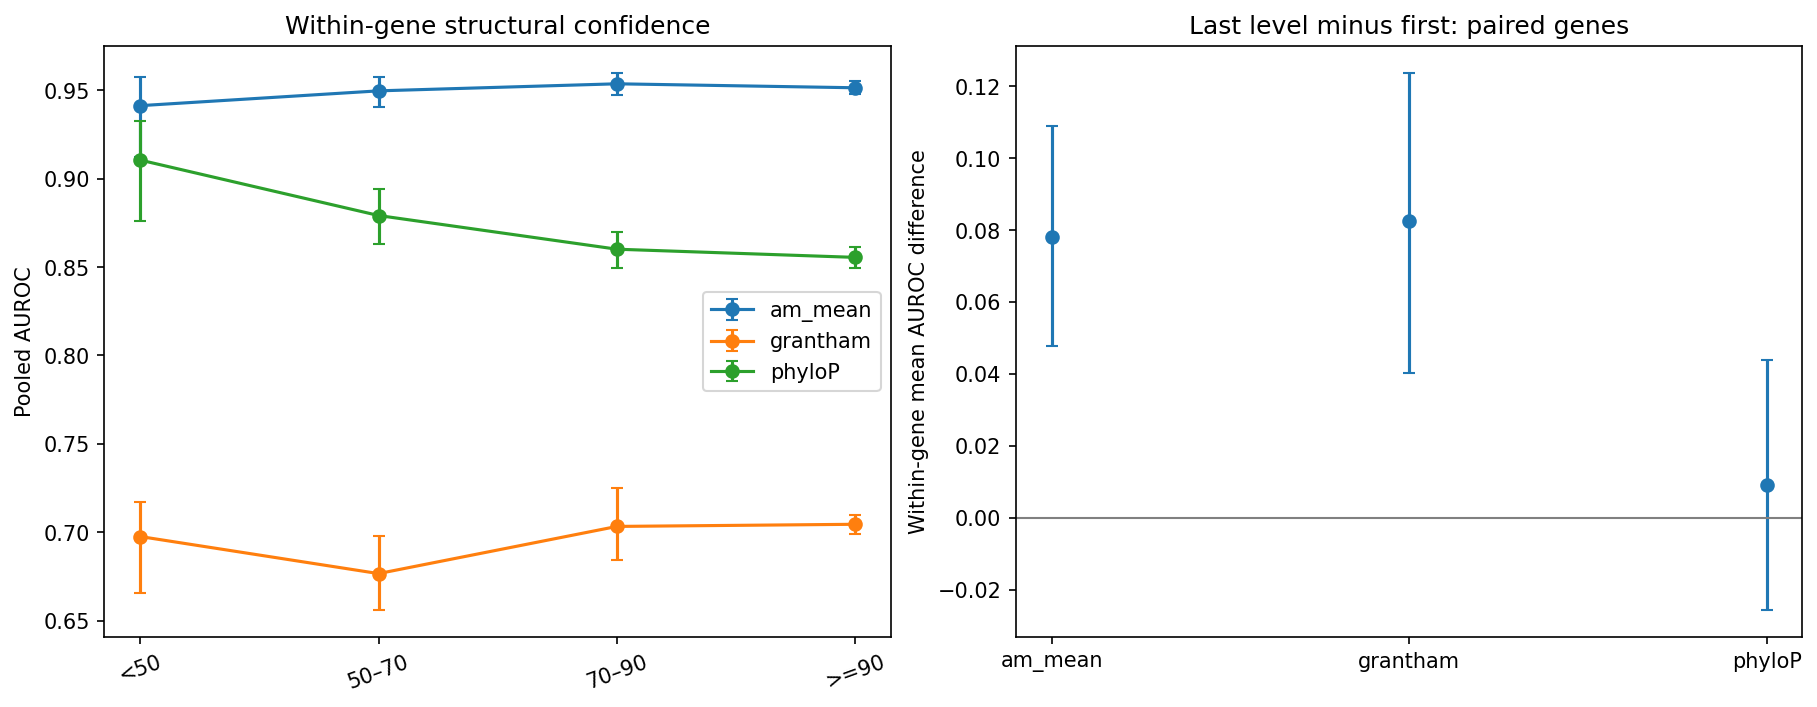

In [10]:
SCORES=['am_mean','am_min','am_max','grantham','phyloP','gene_mean_phyloP'];B=2000;rng=np.random.default_rng(20260722)
def safe_auc(y,s,w=None):
    y=np.asarray(y);s=np.asarray(s,dtype=float);ok=np.isfinite(s);y=y[ok];s=s[ok]
    return roc_auc_score(y,s,sample_weight=None if w is None else np.asarray(w)[ok]) if len(np.unique(y))==2 else np.nan
# Score sort/tie groups are fixed before resampling genes. Every predictor uses
# the same gene draws so its interval refers to the same biological units.
gene_names=sorted(panel.gene.unique());gene_index={x:i for i,x in enumerate(gene_names)}
arrays={};rows=[]
for level in order:
    d=panel[panel.level==level]
    for score in SCORES:
        x=d.dropna(subset=[score]);s=x[score].to_numpy();idx=np.argsort(s,kind='stable');s=s[idx];y=x.label.to_numpy()[idx];gi=x.gene.map(gene_index).to_numpy()[idx]
        starts=np.r_[0,np.flatnonzero(s[1:]!=s[:-1])+1] if len(s) else np.array([],dtype=int)
        arrays[level,score]=(y,gi,starts)
        rows.append({'level':level,'score':score,'n':len(x),'pathogenic':int(x.label.sum()),'genes':x.gene.nunique(),'AUROC':safe_auc(x.label,x[score])})
curves=pd.DataFrame(rows);draws={key:[] for key in arrays}
for replicate in range(B):
    weights=rng.multinomial(len(gene_names),np.full(len(gene_names),1/len(gene_names)))
    for key,(y,gi,starts) in arrays.items():
        if not len(y):draws[key].append(np.nan);continue
        w=weights[gi];pos=np.add.reduceat(w*y,starts);neg=np.add.reduceat(w*(1-y),starts);den=pos.sum()*neg.sum()
        draws[key].append(float(np.sum(pos*(np.cumsum(neg)-.5*neg))/den) if den else np.nan)
for (level,score),values in draws.items():
    lo,hi=np.nanquantile(values,[.025,.975]);m=(curves.level==level)&(curves.score==score);curves.loc[m,'ci_low']=lo;curves.loc[m,'ci_high']=hi
contrasts=[]
for score in SCORES:
    v=np.asarray(draws[order[-1],score])-np.asarray(draws[order[0],score]);lo,hi=np.nanquantile(v,[.025,.975]);d=curves[curves.score==score].set_index('level')
    contrasts.append({'score':score,'delta_last_minus_first':d.loc[order[-1],'AUROC']-d.loc[order[0],'AUROC'],'ci_low':lo,'ci_high':hi})
contrasts=pd.DataFrame(contrasts)
# The paired endpoint panel requires >=2 variants of each label at both ends.
paired_rows=[];alllevel_rows=[]
for gene,d in panel.groupby('gene'):
    arms={lev:d[d.level==lev] for lev in order}
    enough={lev:len(arm)>0 and min(arm.label.value_counts().reindex([0,1],fill_value=0))>=2 for lev,arm in arms.items()}
    if enough[order[0]] and enough[order[-1]]:
        for score in SCORES:
            a=arms[order[0]];b=arms[order[-1]];lo=safe_auc(a.label,a[score]);hi=safe_auc(b.label,b[score])
            if np.isfinite(lo+hi):paired_rows.append({'gene':gene,'score':score,'first_AUROC':lo,'last_AUROC':hi,'delta':hi-lo})
    if all(enough.values()):
        for lev,arm in arms.items():
            for score in SCORES:alllevel_rows.append({'gene':gene,'level':lev,'score':score,'AUROC':safe_auc(arm.label,arm[score])})
paired=pd.DataFrame(paired_rows,columns=['gene','score','first_AUROC','last_AUROC','delta']);alllevel=pd.DataFrame(alllevel_rows,columns=['gene','level','score','AUROC']);summary=[]
for score,d in paired.groupby('score'):
    values=d.delta.to_numpy();bs=np.array([rng.choice(values,len(values),replace=True).mean() for _ in range(B)]);lo,hi=np.quantile(bs,[.025,.975]);summary.append({'score':score,'genes':len(values),'mean_delta':values.mean(),'ci_low':lo,'ci_high':hi,'first_mean_AUROC':d.first_AUROC.mean(),'last_mean_AUROC':d.last_AUROC.mean()})
paired_summary=pd.DataFrame(summary)
composition=panel.groupby('level').agg(n=('label','size'),pathogenic_fraction=('label','mean'),genes=('gene','nunique'),mean_grantham=('grantham','mean'),mean_position_phyloP=('phyloP','mean'),mean_gene_phyloP=('gene_mean_phyloP','mean'),mean_cds_length=('cds_len','mean')).reindex(order)
control_rows=[]
for feature in ['phyloP','grantham','cds_len']:
    q=pd.qcut(panel[feature],4,labels=False,duplicates='drop')
    for value in sorted(q.dropna().unique()):
        d=panel.loc[q==value];a=d[d.level==order[0]];b=d[d.level==order[-1]]
        if min(len(a),len(b))>=20 and min(a.label.nunique(),b.label.nunique())==2:
            control_rows.append({'stratify':feature,'quartile':int(value)+1,'first_n':len(a),'last_n':len(b),'AM_delta':safe_auc(b.label,b.am_mean)-safe_auc(a.label,a.am_mean)})
controls=pd.DataFrame(control_rows)
display(curves);display(contrasts);display(paired_summary);display(composition);display(controls)
fig,axes=plt.subplots(1,2,figsize=(12,4.6),layout='constrained')
for score in ['am_mean','grantham','phyloP']:
    d=curves[curves.score==score].set_index('level').reindex(order);y=d.AUROC.to_numpy();axes[0].errorbar(range(len(order)),y,yerr=np.maximum(0,np.array([y-d.ci_low,d.ci_high-y])),marker='o',label=score,capsize=3)
axes[0].set(xticks=range(len(order)),xticklabels=order,ylabel='Pooled AUROC',title=AXIS);axes[0].tick_params(axis='x',labelrotation=20);axes[0].legend()
if not paired_summary.empty:
    s=paired_summary[paired_summary.score.isin(['am_mean','grantham','phyloP'])];y=s.mean_delta.to_numpy();axes[1].errorbar(range(len(s)),y,yerr=np.maximum(0,np.array([y-s.ci_low,s.ci_high-y])),fmt='o',capsize=3);axes[1].axhline(0,color='grey',lw=1);axes[1].set(xticks=range(len(s)),xticklabels=s.score,ylabel='Within-gene mean AUROC difference',title='Last level minus first: paired genes')
else:axes[1].text(.1,.5,'No eligible paired genes',transform=axes[1].transAxes)
show_figure(fig);plt.close(fig)
for name,table in [('variants',panel),('curves',curves),('contrasts',contrasts),('paired_genes',paired),('paired_summary',paired_summary),('all_levels_same_genes',alllevel),('composition',composition.reset_index()),('controls',controls)]:table.to_csv(OUTPUT/(name+'.csv.gz' if name=='variants' else name+'.csv'),index=False)


## 6. Result and decision

Positive last-minus-first differences indicate better discrimination at higher levels. The within-gene interval drives the directional interpretation when paired genes are available; pooled estimates alone cannot remove gene composition.


In [11]:
pool=contrasts.set_index('score').loc['am_mean'];pair=paired_summary[paired_summary.score=='am_mean'] if not paired_summary.empty else pd.DataFrame()
if pair.empty:
    decision='Do not assert a gene-independent axis effect: the specified endpoint panel has no eligible paired genes. Pooled results describe the available cohort and may reflect gene composition.'
elif pair.iloc[0].ci_low>0:
    decision='Retain a directional association: AlphaMissense discrimination is better at the last level than at the first within the same genes. The reference contrasts and strata characterize whether this is shared biological difficulty.'
elif pair.iloc[0].ci_high<0:
    decision='The paired within-gene result runs opposite to the proposed higher-feature advantage. Reject that directional claim; the calculated negative association remains visible.'
else:
    decision='Do not retain a supported within-gene directional effect: the endpoint contrast interval includes zero. A pooled association alone is insufficient.'
if not pair.empty and np.sign(pool.delta_last_minus_first)!=np.sign(pair.iloc[0].mean_delta):decision+=' The pooled and within-gene point estimates have opposite signs, showing sensitivity to gene composition.'
print(decision)
receipt={'axis':AXIS,'sources':source_receipts,'variants':len(panel),'bootstrap_replicates':B,'bootstrap_unit':'gene','seed':20260722,'decision':decision,'host':platform.node(),'elapsed_seconds':time.time()-STARTED,'outputs':{p.name:sha256_file(p) for p in OUTPUT.glob('*.csv*')}}
(OUTPUT/'execution.json').write_text(json.dumps(receipt,indent=2)+'\n')


Retain a directional association: AlphaMissense discrimination is better at the last level than at the first within the same genes. The reference contrasts and strata characterize whether this is shared biological difficulty.


2803